# CardioIA Fase 2 | Ir Além 2: Diagnóstico visual de ECG com rede neural MLP

Objetivo: classificar batimentos cardíacos em **normal** ou **anormal** a partir de **imagens** do sinal de ECG, usando um Perceptron Multicamadas (MLP) em Keras.

**Dataset:** [ECG Heartbeat Categorization (Kaggle)](https://www.kaggle.com/datasets/shayanfazeli/heartbeat). Uso a parte **PTB Diagnostic** (`ptbdb_normal.csv` e `ptbdb_abnormal.csv`), que já é binária: normal vs. anormal (infarto e outras alterações).

Cada linha do CSV é **um batimento**: 187 valores do sinal (já normalizados entre 0 e 1) + a última coluna com o rótulo. Como a atividade pede imagens, o fluxo é:

1. Carregar os sinais
2. **Desenhar cada batimento como imagem** (tons de cinza)
3. **Redimensionar** e normalizar os pixels
4. Achatar a imagem num vetor e treinar o MLP
5. Avaliar

> Feito para rodar no **Google Colab** (Ambiente de execução > Executar tudo). Projeto acadêmico, não usar para diagnóstico.

## 1. Bibliotecas

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__)

I0000 00:00:1791670482.496344     216 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791670495.770707     216 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791670502.386588     216 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


## 2. Baixando o dataset

Tenta baixar direto do Kaggle com `kagglehub`. Se não funcionar, baixe o zip no link acima, e faça upload de `ptbdb_normal.csv` e `ptbdb_abnormal.csv` na pasta `data/` (no Colab: ícone de pasta na lateral).

In [2]:
PASTA = "data"
arquivos = ["ptbdb_normal.csv", "ptbdb_abnormal.csv"]

if not all(os.path.exists(os.path.join(PASTA, a)) for a in arquivos):
    try:
        import kagglehub
        PASTA = kagglehub.dataset_download("shayanfazeli/heartbeat")
        print("Baixado em:", PASTA)
    except Exception as e:
        print("Não consegui baixar automaticamente:", e)
        print("Faça o upload manual dos dois CSVs na pasta data/ e rode de novo.")

normal = pd.read_csv(os.path.join(PASTA, "ptbdb_normal.csv"), header=None)
anormal = pd.read_csv(os.path.join(PASTA, "ptbdb_abnormal.csv"), header=None)
print("Normais:", normal.shape, "| Anormais:", anormal.shape)

Normais: (4046, 188) | Anormais: (10506, 188)


## 3. Organizando os dados

A última coluna já é o rótulo (0 = normal, 1 = anormal). Junto as duas tabelas e separo sinal (`X_sinal`) e rótulo (`y`).

In [3]:
dados = pd.concat([normal, anormal], ignore_index=True)
X_sinal = dados.iloc[:, :-1].values.astype("float32")   # 187 pontos por batimento
y = dados.iloc[:, -1].values.astype("int32")

print("Total de batimentos:", len(y))
print(pd.Series(y).map({0: "normal", 1: "anormal"}).value_counts())

Total de batimentos: 14552
anormal    10506
normal      4046
Name: count, dtype: int64


A base é **desbalanceada** (tem bem mais anormais). Vou compensar isso no treino com `class_weight`, senão o modelo aprende a chutar "anormal" e ainda assim parece bom na acurácia.

## 4. Transformando sinal em imagem

Cada batimento vira uma imagem em tons de cinza: fundo preto (0) e a linha do ECG branca (255), como se fosse o traçado impresso do eletro.

Faço o desenho com NumPy puro (mais rápido que gerar milhares de gráficos com matplotlib):

- eixo X: os 187 pontos no tempo
- eixo Y: a amplitude do sinal, convertida em linha da imagem
- entre um ponto e o próximo, pinto a coluna inteira para a linha ficar contínua

In [4]:
ALTURA_ORIGINAL = 128

def sinal_para_imagem(sinal, altura=ALTURA_ORIGINAL):
    largura = len(sinal)
    img = np.zeros((altura, largura), dtype=np.uint8)
    # amplitude 0..1 -> linha da imagem (0 fica embaixo, por isso o "altura - 1 -")
    linhas = (altura - 1 - np.clip(sinal, 0, 1) * (altura - 1)).astype(int)
    for x in range(largura):
        y0 = linhas[x]
        y1 = linhas[x + 1] if x + 1 < largura else y0
        topo, base = min(y0, y1), max(y0, y1)
        img[topo:base + 1, x] = 255
    return img

exemplo = sinal_para_imagem(X_sinal[0])
print("Imagem original:", exemplo.shape, exemplo.dtype)

Imagem original: (128, 187) uint8


### Vendo alguns exemplos (e salvando para o README)

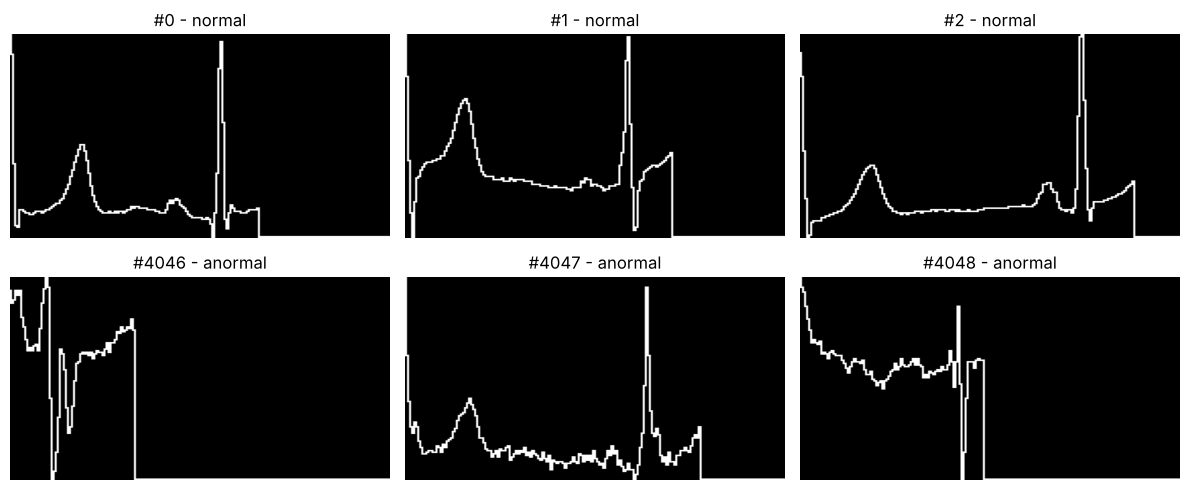

In [5]:
os.makedirs("exemplos", exist_ok=True)
idx_normais = np.where(y == 0)[0][:3]
idx_anormais = np.where(y == 1)[0][:3]

fig, axes = plt.subplots(2, 3, figsize=(12, 5))
for ax, i in zip(axes.flat, list(idx_normais) + list(idx_anormais)):
    img = sinal_para_imagem(X_sinal[i])
    rotulo = "normal" if y[i] == 0 else "anormal"
    ax.imshow(img, cmap="gray", aspect="auto")
    ax.set_title(f"#{i} - {rotulo}")
    ax.axis("off")
    plt.imsave(f"exemplos/ecg_{rotulo}_{i}.png", img, cmap="gray")
plt.tight_layout()
plt.savefig("exemplos/grade_exemplos.png", dpi=100)
plt.show()

## 5. Redimensionando e normalizando

Um MLP recebe um vetor, não uma imagem. Uma imagem 128x187 vira um vetor de 23.936 números, o que é pesado demais para um MLP simples.

Então:

1. **Redimensiono** para 32x64 (2.048 pixels). Perde detalhe, mas o formato da onda continua reconhecível.
2. **Normalizo** os pixels de 0..255 para 0..1 (rede neural treina bem melhor com valores pequenos).
3. **Achato** (flatten) cada imagem num vetor de 2.048 posições.

Imagens prontas: (14552, 32, 64, 1)


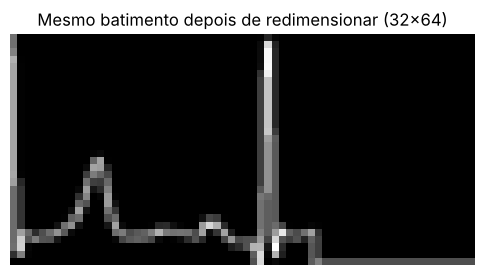

Entrada do MLP: (14552, 2048)


In [6]:
ALTURA, LARGURA = 32, 64

def preparar_imagens(sinais, lote=2000):
    saida = []
    for ini in range(0, len(sinais), lote):
        imgs = np.stack([sinal_para_imagem(s) for s in sinais[ini:ini + lote]])
        imgs = imgs[..., np.newaxis].astype("float32") / 255.0          # tons de cinza 0..1, 1 canal
        imgs = tf.image.resize(imgs, (ALTURA, LARGURA), antialias=True).numpy()
        saida.append(imgs)
    return np.concatenate(saida)

X_img = preparar_imagens(X_sinal)
print("Imagens prontas:", X_img.shape)

plt.figure(figsize=(6, 3))
plt.imshow(X_img[0, :, :, 0], cmap="gray", aspect="auto")
plt.title("Mesmo batimento depois de redimensionar (32x64)")
plt.axis("off")
plt.show()

X = X_img.reshape(len(X_img), -1)   # flatten
print("Entrada do MLP:", X.shape)

## 6. Treino, validação e teste

- 70% treino, 15% validação (para acompanhar o treino e parar na hora certa), 15% teste (só olho no final)
- `stratify` mantém a proporção normal/anormal em todas as partes

In [7]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)
print("Treino:", X_train.shape, "| Validação:", X_val.shape, "| Teste:", X_test.shape)

pesos = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight = dict(enumerate(pesos))
print("Peso por classe:", {k: round(v, 2) for k, v in class_weight.items()})

Treino: (10186, 2048) | Validação: (2183, 2048) | Teste: (2183, 2048)
Peso por classe: {0: np.float64(1.8), 1: np.float64(0.69)}


## 7. A rede MLP

- **Entrada:** 2.048 pixels
- **Camadas ocultas:** 256 → 128 → 64 neurônios com ReLU
- **Dropout:** desliga neurônios aleatórios durante o treino para o modelo não decorar (overfitting)
- **Saída:** 1 neurônio com sigmoid, que devolve a probabilidade de ser anormal
- **Perda:** binary crossentropy (problema binário) e otimizador Adam

In [8]:
modelo = keras.Sequential([
    layers.Input(shape=(X.shape[1],)),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])

modelo.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.Recall(name="recall")],
)
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 565,761 (2.16 MB)

 Trainable params: 565,761 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
parar_cedo = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

historico = modelo.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=80,
    batch_size=64,
    class_weight=class_weight,
    callbacks=[parar_cedo],
    verbose=2,
)

Epoch 1/80


160/160 - 2s - 15ms/step - accuracy: 0.8572 - loss: 0.3342 - recall: 0.8618 - val_accuracy: 0.9290 - val_loss: 0.1720 - val_recall: 0.9410


Epoch 2/80


160/160 - 1s - 7ms/step - accuracy: 0.9383 - loss: 0.1674 - recall: 0.9366 - val_accuracy: 0.9492 - val_loss: 0.1260 - val_recall: 0.9740


Epoch 3/80


...

160/160 - 1s - 6ms/step - accuracy: 0.9953 - loss: 0.0130 - recall: 0.9947 - val_accuracy: 0.9753 - val_loss: 0.1168 - val_recall: 0.9772


Epoch 14/80


160/160 - 1s - 9ms/step - accuracy: 0.9937 - loss: 0.0182 - recall: 0.9936 - val_accuracy: 0.9780 - val_loss: 0.1158 - val_recall: 0.9784


Epoch 15/80


160/160 - 1s - 6ms/step - accuracy: 0.9927 - loss: 0.0179 - recall: 0.9925 - val_accuracy: 0.9785 - val_loss: 0.1071 - val_recall: 0.9784


## 8. Curvas de aprendizado

Se a linha de treino continua melhorando e a de validação piora, é overfitting. O EarlyStopping para o treino quando a validação para de melhorar e volta para os melhores pesos.

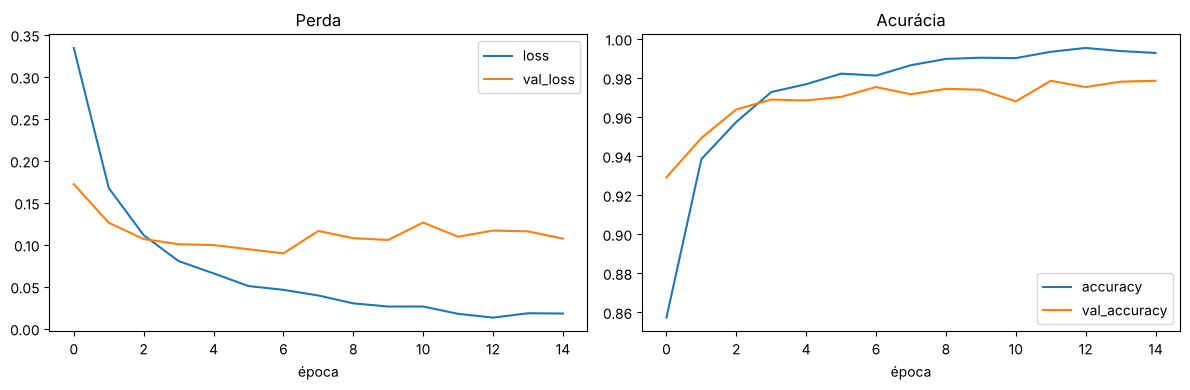

In [10]:
h = pd.DataFrame(historico.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
h[["loss", "val_loss"]].plot(ax=axes[0], title="Perda")
h[["accuracy", "val_accuracy"]].plot(ax=axes[1], title="Acurácia")
for ax in axes:
    ax.set_xlabel("época")
plt.tight_layout()
plt.savefig("exemplos/curvas_treino.png", dpi=100)
plt.show()

## 9. Avaliação no conjunto de teste

Acurácia no teste: 97.53%
Recall (anormais detectados): 98.79%



              precision    recall  f1-score   support

      normal       0.97      0.94      0.95       607
     anormal       0.98      0.99      0.98      1576

    accuracy                           0.98      2183
   macro avg       0.97      0.97      0.97      2183
weighted avg       0.98      0.98      0.98      2183



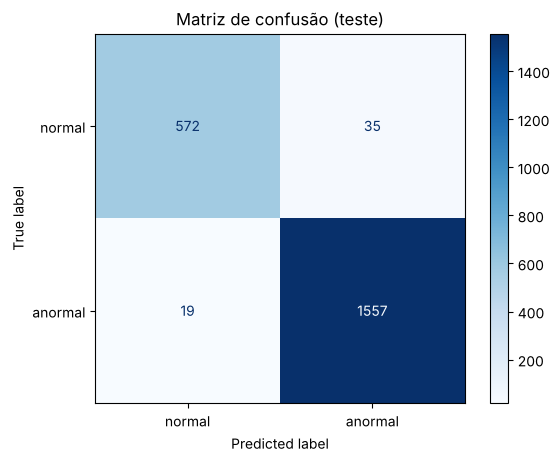

In [11]:
perda, acc, rec = modelo.evaluate(X_test, y_test, verbose=0)
print(f"Acurácia no teste: {acc:.2%}")
print(f"Recall (anormais detectados): {rec:.2%}")

prob = modelo.predict(X_test, verbose=0).ravel()
pred = (prob >= 0.5).astype(int)
print()
print(classification_report(y_test, pred, target_names=["normal", "anormal"]))

ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["normal", "anormal"], cmap="Blues")
plt.title("Matriz de confusão (teste)")
plt.savefig("exemplos/matriz_confusao.png", dpi=100, bbox_inches="tight")
plt.show()

## 10. Onde o modelo errou?

Ver os erros ajuda a entender o modelo. Abaixo, alguns batimentos do teste que ele classificou errado.

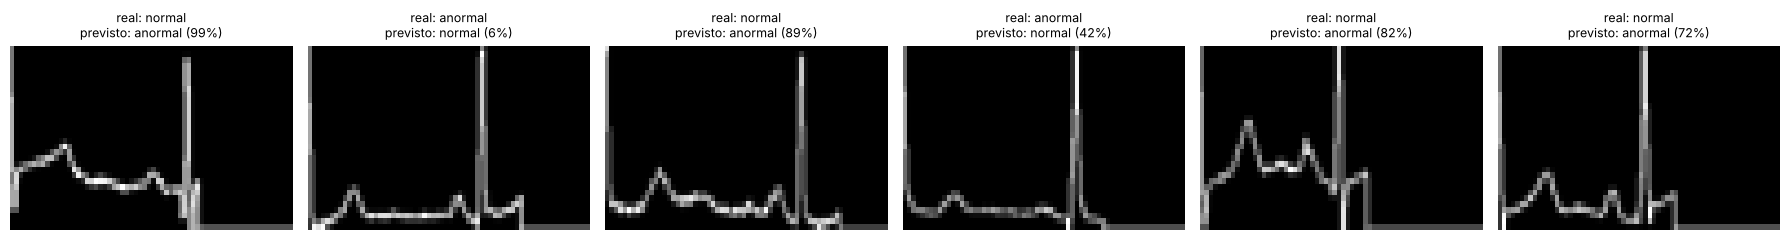

In [12]:
erros = np.where(pred != y_test)[0][:6]
if len(erros):
    fig, axes = plt.subplots(1, len(erros), figsize=(3 * len(erros), 2.5))
    axes = np.atleast_1d(axes)
    nomes = ["normal", "anormal"]
    for ax, i in zip(axes, erros):
        ax.imshow(X_test[i].reshape(ALTURA, LARGURA), cmap="gray", aspect="auto")
        ax.set_title(f"real: {nomes[y_test[i]]}\nprevisto: {nomes[pred[i]]} ({prob[i]:.0%})", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Nenhum erro no teste.")

## 11. Conclusões

- Acurácia no teste: **97,5%**. Recall dos anormais: **98,8%** (1.557 de 1.576 batimentos anormais detectados).
- Curvas de treino: a perda de treino continuou caindo até perto de zero, mas a de validação parou de melhorar na época 7 (val_loss 0,09) e começou a oscilar para cima. Isso é o começo de overfitting: a rede passa a decorar o treino. O EarlyStopping esperou 8 épocas sem melhora, parou na época 15 e devolveu os pesos da época 7.
- O modelo errou mais os **normais**: 35 normais viraram anormais (falso alarme) contra 19 anormais classificados como normais (falso negativo). Faz sentido, porque os normais são minoria na base (28%), mesmo com o `class_weight`. Para triagem esse lado do erro é o menos grave: um falso alarme gera um exame extra, enquanto um falso negativo manda para casa alguém que precisava de atenção.

**Limitações:**

- Um MLP trata cada pixel como independente e não entende que pixels vizinhos formam uma linha. Redes convolucionais (CNN, que vimos no 1º ano) aproveitam isso e costumam ir melhor com imagens.
- Transformar o sinal em imagem descarta informação; o próprio sinal 1D com 187 pontos é uma entrada mais leve para a rede. A imagem aqui é para seguir o enunciado e treinar o pipeline de visão computacional.
- Os batimentos de um mesmo paciente podem cair no treino e no teste ao mesmo tempo (a base não traz ID de paciente), o que tende a deixar a acurácia otimista.
- Modelo de apoio, não substitui um cardiologista.